# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [1]:
# If on colab, uncomment the following lines


!wget -q -O car_data.csv https://raw.githubusercontent.com/girafe-ai/ml-course/23f_basic/homeworks/lab01_ml_pipeline/car_data.csv
print("Данные загружены")


Данные загружены


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35, random_state=42)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [3]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,822,95,41,82,170,65,9,145,46,19,145,163,314,140,64,4,8,199,207
1,486,104,57,103,222,72,12,221,30,25,177,223,718,218,72,11,12,186,195
2,182,91,42,66,169,66,7,145,44,19,140,169,325,159,67,4,0,201,207
3,375,109,52,95,189,58,4,227,29,25,158,262,776,217,82,0,19,187,186
4,528,95,47,73,195,70,7,167,38,20,152,184,430,185,69,9,19,200,206
5,223,81,44,72,139,60,6,153,44,19,146,180,347,178,81,1,15,182,186
6,840,93,34,66,140,56,7,130,51,18,120,151,251,114,62,5,29,201,207
7,593,89,43,77,147,54,8,144,46,19,146,163,308,174,64,13,5,194,201
8,346,117,52,110,228,65,12,212,31,24,163,228,668,220,66,21,25,194,205
9,357,109,49,109,193,59,10,207,32,24,156,225,635,213,70,13,31,191,202


Methods `describe` and `info` deliver some useful information.

In [4]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,425.723133,93.520947,44.675774,81.801457,168.204007,61.644809,8.457195,167.327869,41.273224,20.468124,147.438980,186.734062,431.540984,173.763206,72.158470,6.522769,12.646630,188.998179,195.854281
std,242.288797,8.063277,6.154680,15.928751,33.047995,7.110666,3.945857,32.506680,7.777590,2.526030,14.631309,30.436279,171.479332,31.793047,7.335198,4.980796,8.833356,6.298389,7.449629
min,0.000000,76.000000,33.000000,42.000000,104.000000,47.000000,2.000000,114.000000,26.000000,17.000000,118.000000,131.000000,191.000000,112.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,217.000000,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,146.000000,34.000000,19.000000,136.000000,167.000000,317.000000,148.000000,67.000000,2.000000,6.000000,184.000000,191.000000
50%,430.000000,93.000000,44.000000,79.000000,165.000000,61.000000,8.000000,157.000000,43.000000,20.000000,145.000000,177.000000,363.000000,173.000000,71.000000,6.000000,11.000000,189.000000,197.000000
75%,636.000000,99.000000,49.000000,98.000000,195.000000,66.000000,10.000000,196.000000,46.000000,23.000000,159.000000,216.000000,576.000000,196.000000,75.000000,10.000000,19.000000,193.000000,201.000000
max,845.000000,117.000000,59.000000,110.000000,306.000000,126.000000,52.000000,265.000000,59.000000,29.000000,186.000000,288.000000,1018.000000,268.000000,127.000000,22.000000,40.000000,206.000000,211.000000


In [5]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [6]:
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Масштабируем признаки
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Кодируем целевую переменную в числа (нужно для xgboost и удобно для моделей)
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

print("Train scaled shape:", X_train_scaled.shape)
print("Test scaled shape:", X_test_scaled.shape)
print("Classes:", list(le.classes_))
print("Encoded labels example:", y_train_encoded[:10])


Train scaled shape: (549, 19)
Test scaled shape: (297, 19)
Classes: ['bus', 'opel', 'saab', 'van']
Encoded labels example: [3 1 0 0 0 0 1 2 2 2]


Сначала масштабировал признаки через StandardScaler, чтобы они были примерно в одном масштабе. Это нужно т.к. признаки имеют разные значения и некоторые могут сильнее влиять на модель из-за размера.

Также перевел названия классов автомобилей в числа с помощью LabelEncoder, чтобы их можно было использовать при обучении моделей.

Масштабирование и кодирование сначала обучаются на тренировочной выборке, а потом применяются к тестовой. Чтобы не использовать информацию из тестовых данных заранее.

#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Best params: {'log_reg__C': 1, 'log_reg__penalty': 'l1'}
Best CV F1 (macro): 0.7934
Test accuracy: 0.8047
Test F1 (macro): 0.7968


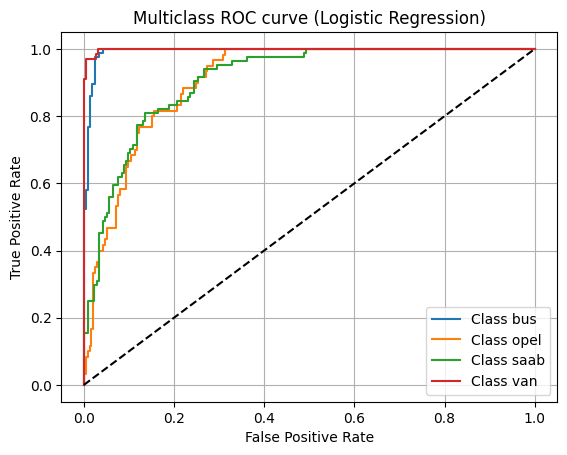

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_curve
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Сетка гиперпараметров (простая и детерминированная)
param_grid = {
    "log_reg__C": [0.01, 0.1, 1, 10, 100],
    "log_reg__penalty": ["l1", "l2"]
}


log_reg = LogisticRegression(
    multi_class="multinomial",
    solver="saga",
    tol=1e-3,
    max_iter=500,
    n_jobs=-1,
    random_state=42
)

grid = GridSearchCV(

    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("log_reg", log_reg)
    ]),

    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train_encoded)

best_log_reg = grid.best_estimator_.named_steps["log_reg"]
print("Best params:", grid.best_params_)
print("Best CV F1 (macro): {:.4f}".format(grid.best_score_))

y_pred_lr = best_log_reg.predict(X_test_scaled)
y_proba_lr = best_log_reg.predict_proba(X_test_scaled)

acc_lr = accuracy_score(y_test_encoded, y_pred_lr)
f1_lr = f1_score(y_test_encoded, y_pred_lr, average="macro")

print("Test accuracy: {:.4f}".format(acc_lr))
print("Test F1 (macro): {:.4f}".format(f1_lr))

# ROC-кривые One-vs-Rest без scikit-plot
classes = np.unique(y_test_encoded)
y_test_bin = label_binarize(y_test_encoded, classes=classes)

plt.figure()
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_lr[:, i])
    label = f"Class {le.inverse_transform([cls])[0]}"
    plt.plot(fpr, tpr, label=label)

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC curve (Logistic Regression)")
plt.legend()
plt.grid(True)
plt.show()


После подбора гиперпараметров лучшие результаты получились при C=1 и L1 регуляризации.

На тестовой выборке accuracy составила 0.8047, а F1 около 0.7968. Т.е. модель правильно определяет примерно 80% автомобилей, в целом результат неплохой.

По ROC-кривым видно что bus и van модель определяет довольно хорошо. А вот opel и saab различаются хуже, видимо их характеристики достаточно похожи, поэтому модель иногда их путает.

In [8]:
# You might use this command to install scikit-plot.
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding
# virtual environment instead

# ! pip install scikit-plot

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot.

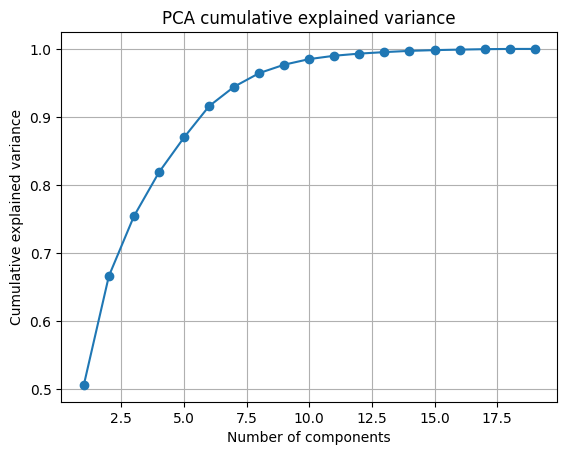

In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

pca_full = PCA()
pca_full.fit(X_train_scaled)

explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained_variance_ratio)
components = np.arange(1, len(explained_variance_ratio) + 1)

plt.figure()
plt.plot(components, cumulative, marker="o")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative explained variance")
plt.grid(True)
plt.show()


По графику видно что первые компоненты объясняют большую часть дисперсии. Примерно на 8 компонентах сохраняется около 97% информации по дисперсии, а дальше график почти перестает расти. Поэтому скорее всего нет смысла оставлять все 19 признаков можно использовать 8.

#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [10]:
import numpy as np
from sklearn.decomposition import PCA

cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_components_opt = int(np.argmax(cumulative >= 0.95) + 1)

print(f"Number of components to explain >=95% variance: {n_components_opt}")

pca = PCA(n_components=n_components_opt)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Train PCA shape:", X_train_pca.shape)
print("Test PCA shape:", X_test_pca.shape)

Number of components to explain >=95% variance: 8
Train PCA shape: (549, 8)
Test PCA shape: (297, 8)


Количество компонент такое что объясняет 95% дисперсии.
Оно позволяет сократить размерность данных при сохроанении почти всей
важной информации

**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Best params (PCA): {'log_reg__C': 0.1, 'log_reg__penalty': 'l2'}
Best CV F1 (macro, PCA): 0.5522
Test accuracy (PCA): 0.6296
Test F1 (macro, PCA): 0.6146


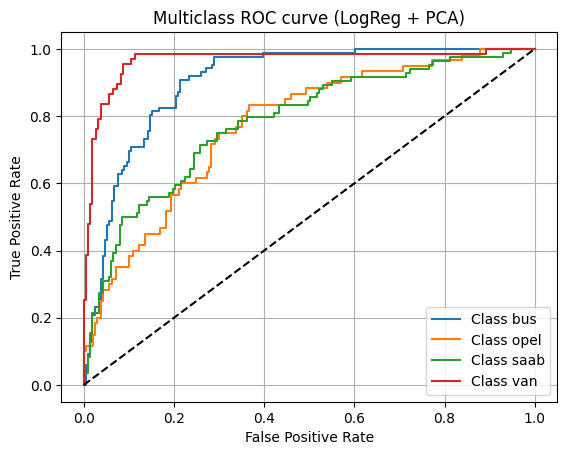

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_curve
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


param_grid_pca = {
    "log_reg__C": [0.01, 0.1, 1, 10, 100],
    "log_reg__penalty": ["l1", "l2"]
}


log_reg_pca = LogisticRegression(
    multi_class="multinomial",
    solver="saga",
    tol=1e-3,
    max_iter=500,
    n_jobs=-1,
    random_state=42
)

grid_pca = GridSearchCV(

    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95)),
        ("log_reg", log_reg_pca)
    ]),
    param_grid=param_grid_pca,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_pca.fit(X_train, y_train_encoded)

best_log_reg_pca = grid_pca.best_estimator_
print("Best params (PCA):", grid_pca.best_params_)
print("Best CV F1 (macro, PCA): {:.4f}".format(grid_pca.best_score_))

y_pred_lr_pca = best_log_reg_pca.predict(X_test)
y_proba_lr_pca = best_log_reg_pca.predict_proba(X_test)

acc_lr_pca = accuracy_score(y_test_encoded, y_pred_lr_pca)
f1_lr_pca = f1_score(y_test_encoded, y_pred_lr_pca, average="macro")

print("Test accuracy (PCA): {:.4f}".format(acc_lr_pca))
print("Test F1 (macro, PCA): {:.4f}".format(f1_lr_pca))

classes = np.unique(y_test_encoded)
y_test_bin = label_binarize(y_test_encoded, classes=classes)

plt.figure()
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_lr_pca[:, i])
    label = f"Class {le.inverse_transform([cls])[0]}"
    plt.plot(fpr, tpr, label=label)

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC curve (LogReg + PCA)")
plt.legend()
plt.grid(True)
plt.show()


После PCA количество признаков уменьшилось с 19 до 8. Но качество логистической регрессии довольно сильно упало. Accuracy снизилась с 0.8047 до 0.6296, F1 с 0.7968 до 0.6146.

Скорее всего при уменьшении размерности потерялась часть информации которая была важна для классификации. Хотя PCA и сохраняет больше 95% дисперсии, это не значит что сохраняются все полезные для модели признаки.

По ROC-кривым тоже видно что качество стало хуже, особенно для bus, opel и saab. Поэтому в данном случае использование PCA ухудшило результат.

#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

param_grid_dt = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 9, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt = DecisionTreeClassifier(random_state=42)

grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_dt.fit(X_train_scaled, y_train_encoded)

best_dt = grid_dt.best_estimator_
print("Best params (Decision tree):", grid_dt.best_params_)
print("Best CV F1 (macro, tree): {:.4f}".format(grid_dt.best_score_))

y_pred_dt = best_dt.predict(X_test_scaled)
acc_dt = accuracy_score(y_test_encoded, y_pred_dt)
f1_dt = f1_score(y_test_encoded, y_pred_dt, average="macro")

print("Test accuracy (tree): {:.4f}".format(acc_dt))
print("Test F1 (macro, tree): {:.4f}".format(f1_dt))


Best params (Decision tree): {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best CV F1 (macro, tree): 0.6960
Test accuracy (tree): 0.7104
Test F1 (macro, tree): 0.6956


Для дерева решений подобраны гиперпараметры через кросс-валидацию. Лучшая глубина получилась 8, min_samples_leaf = 1 и min_samples_split = 5.

На тестовой выборке accuracy составила 0.7104, а F1 около 0.6956. Результат хуже чем у логистической регрессии без PCA, но лучше чем после PCA.

Для дерева использовались все 19 признаков без PCA, поскольку оно само выбирает признаки для разделения. Возможно логистическая регрессия лучше подходит для этого датасета, поэтому и показывает более высокое качество.

#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

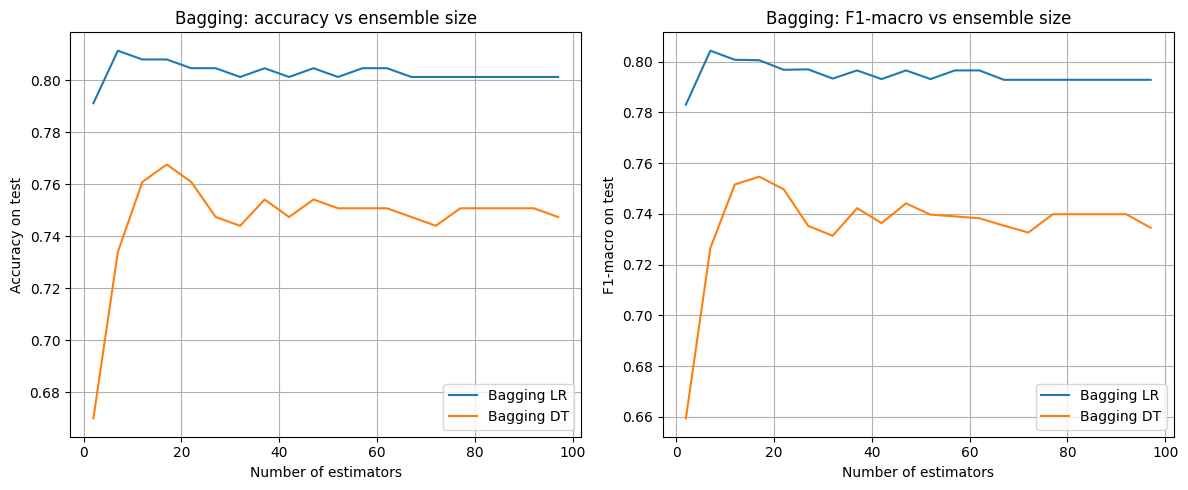

In [13]:
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import matplotlib.pyplot as plt

# Диапазон числа базовых моделей
n_estimators_range = np.arange(2, 101, 5)

bagging_lr_acc, bagging_lr_f1 = [], []
bagging_dt_acc, bagging_dt_f1 = [], []

# Бэггинг для логистической регрессии
for n in n_estimators_range:
    bag_lr = BaggingClassifier(
        estimator=best_log_reg,
        n_estimators=n,
        n_jobs=-1,
        random_state=42
    )
    bag_lr.fit(X_train_scaled, y_train_encoded)
    y_pred = bag_lr.predict(X_test_scaled)
    bagging_lr_acc.append(accuracy_score(y_test_encoded, y_pred))
    bagging_lr_f1.append(f1_score(y_test_encoded, y_pred, average="macro"))

# Бэггинг для дерева решений
for n in n_estimators_range:
    bag_dt = BaggingClassifier(
        estimator=best_dt,
        n_estimators=n,
        n_jobs=-1,
        random_state=42
    )
    bag_dt.fit(X_train_scaled, y_train_encoded)
    y_pred = bag_dt.predict(X_test_scaled)
    bagging_dt_acc.append(accuracy_score(y_test_encoded, y_pred))
    bagging_dt_f1.append(f1_score(y_test_encoded, y_pred, average="macro"))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(n_estimators_range, bagging_lr_acc, label="Bagging LR")
plt.plot(n_estimators_range, bagging_dt_acc, label="Bagging DT")
plt.xlabel("Number of estimators")
plt.ylabel("Accuracy on test")
plt.title("Bagging: accuracy vs ensemble size")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(n_estimators_range, bagging_lr_f1, label="Bagging LR")
plt.plot(n_estimators_range, bagging_dt_f1, label="Bagging DT")
plt.xlabel("Number of estimators")
plt.ylabel("F1-macro on test")
plt.title("Bagging: F1-macro vs ensemble size")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

По графикам видно что при увеличении числа моделей качество сначала растет, но потом практически перестает меняться. У логистической регрессии лучший результат получается примерно при 7 моделях, дальше качество снижается и остаетмся примерно на одном уровне

У деревьев качество растет менее равномерно. Максимум получается где-то на 17 деревьях, дальше результат колеблется но особо не меняется. В целом Bagging логистических регрессий работает лучше чем Bagging деревьев.

Гиперпараметры из пункта 2.5 подбирались для одиночного дерева, поэтому для ансамбля они не обязательно будут оптимальными. В Bagging деревья обучаются на разных подвыборках и их ошибки частично компенсируются. Поэтому более глубокие деревья могут показать лучший результат чем по отдельности.

#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

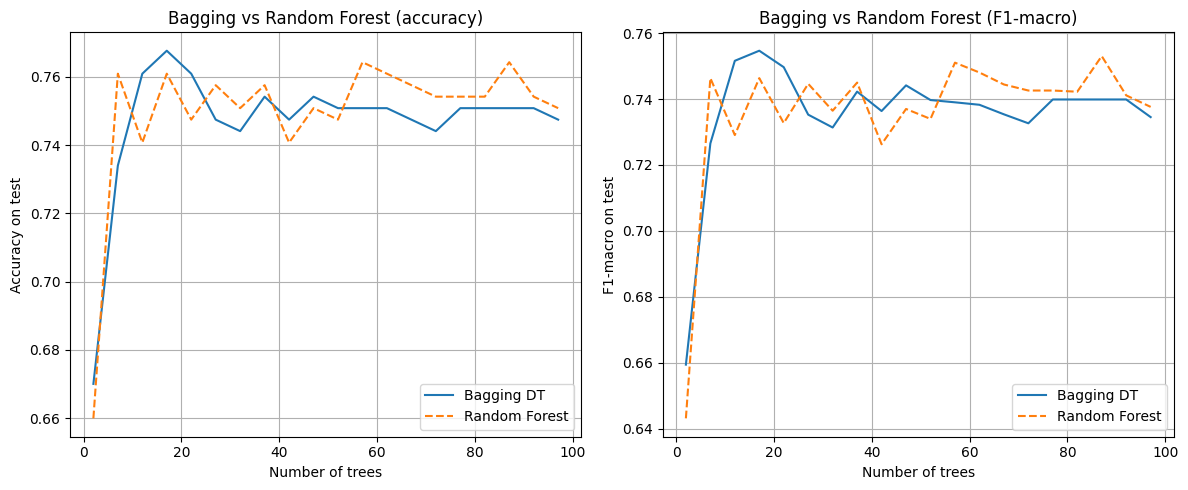

Best n_estimators for RandomForest (by F1-macro): 87


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import numpy as np

n_estimators_range = np.arange(2, 101, 5)

rf_acc, rf_f1 = [], []

for n in n_estimators_range:
    rf = RandomForestClassifier(
        n_estimators=n,
        max_depth=best_dt.max_depth,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_scaled, y_train_encoded)
    y_pred = rf.predict(X_test_scaled)
    rf_acc.append(accuracy_score(y_test_encoded, y_pred))
    rf_f1.append(f1_score(y_test_encoded, y_pred, average="macro"))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(n_estimators_range, bagging_dt_acc, label="Bagging DT")
plt.plot(n_estimators_range, rf_acc, label="Random Forest", linestyle="--")
plt.xlabel("Number of trees")
plt.ylabel("Accuracy on test")
plt.title("Bagging vs Random Forest (accuracy)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(n_estimators_range, bagging_dt_f1, label="Bagging DT")
plt.plot(n_estimators_range, rf_f1, label="Random Forest", linestyle="--")
plt.xlabel("Number of trees")
plt.ylabel("F1-macro on test")
plt.title("Bagging vs Random Forest (F1-macro)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

best_n_estimators_rf = int(n_estimators_range[np.argmax(rf_f1)])
print("Best n_estimators for RandomForest (by F1-macro):", best_n_estimators_rf)

По графикам видно что Random Forest и Bagging деревьев показывают примерно одинаковое качество. Максимальный F1 у Random Forest получается при 87 деревьях, но уже при меньшем количестве результат довольно близкий. Дальше качество колеблется постоянного роста нет.

В Bagging из пункта 2.6 лучшее количество деревьев было 17, а у логистической регрессии 7. Т.е. оптимальное количество моделей отличается довольно сильно.

Вероятно это связано с тем что Random Forest дополнительно использует случайный выбор признаков при построении деревьев. Из-за этого деревья получаются более разными и их ошибки меньше коррелируют между собой. Но в данном случае это не дало заметного преимущества перед обычным Bagging.

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it?

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

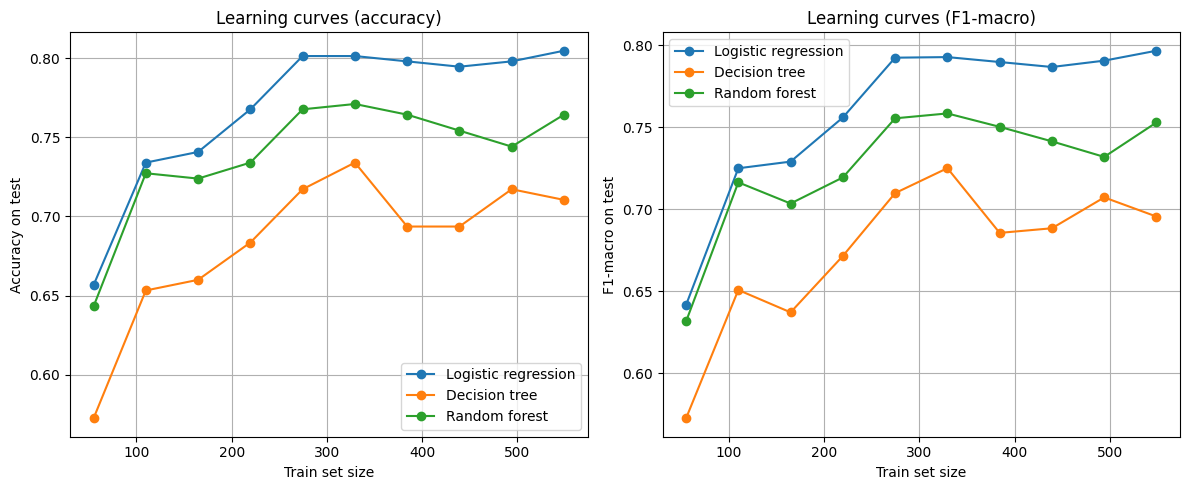

In [15]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt

# Модели с лучшими гиперпараметрами
models = {
    "Logistic regression": best_log_reg,
    "Decision tree": best_dt,
    "Random forest": RandomForestClassifier(
        n_estimators=best_n_estimators_rf,
        max_depth=best_dt.max_depth,
        random_state=42,
        n_jobs=-1
    )
}

# Доли обучающей выборки (без случайного перемешивания)
fractions = np.linspace(0.1, 1.0, 10)

plt.figure(figsize=(12, 5))

for name, base_model in models.items():
    acc_values = []
    f1_values = []
    for frac in fractions:
        n_train = int(len(X_train_scaled) * frac)
        n_train = max(n_train, 2)
        X_sub = X_train_scaled[:n_train]
        y_sub = y_train_encoded[:n_train]

        model = base_model  # переобучаем тот же объект
        model.fit(X_sub, y_sub)
        y_pred = model.predict(X_test_scaled)

        acc_values.append(accuracy_score(y_test_encoded, y_pred))
        f1_values.append(f1_score(y_test_encoded, y_pred, average="macro"))

    train_sizes = fractions * len(X_train_scaled)

    plt.subplot(1, 2, 1)
    plt.plot(train_sizes, acc_values, marker="o", label=name)

    plt.subplot(1, 2, 2)
    plt.plot(train_sizes, f1_values, marker="o", label=name)

plt.subplot(1, 2, 1)
plt.xlabel("Train set size")
plt.ylabel("Accuracy on test")
plt.title("Learning curves (accuracy)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.xlabel("Train set size")
plt.ylabel("F1-macro on test")
plt.title("Learning curves (F1-macro)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

По графикам видно что при увеличении обучающей выборки качество моделей в целом растет. Особенно заметно это в начале когда данных совсем мало.

Лучше всего себя показала логистическая регрессия. Accuracy выросла примерно с 0.66 до 0.80, при этом рост довольно стабильный. После 250-300 объектов качество уже меняется не сильно.

Дерево решений показало самый слабый результат, причем качество заметно колеблется при изменении размера выборки. Видимо дерево достаточно чувствительно к тому какие именно данные попадают в обучение.

Random Forest работает стабильнее одиночного дерева и показывает более высокое качество. Примерно до 300-350 объектов качество растет, потом начинает колебаться примерно на одном уровне.

Получается что увеличение количества обучающих данных в целом полезно для всех трех моделей, но улучшение не всегда равномерное. А логистическая регрессия на этом датасете пока работает лучше остальных.

#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

Rounds:  20 | accuracy: 0.6884 | F1-macro: 0.6657
Rounds:  40 | accuracy: 0.7246 | F1-macro: 0.7080
Rounds:  60 | accuracy: 0.7174 | F1-macro: 0.7037
Rounds:  80 | accuracy: 0.6884 | F1-macro: 0.6847
Rounds: 100 | accuracy: 0.6884 | F1-macro: 0.6894
Rounds: 120 | accuracy: 0.6739 | F1-macro: 0.6752
Rounds: 140 | accuracy: 0.6884 | F1-macro: 0.6894
Rounds: 160 | accuracy: 0.6884 | F1-macro: 0.6894
Rounds: 180 | accuracy: 0.6957 | F1-macro: 0.6978
Rounds: 200 | accuracy: 0.6957 | F1-macro: 0.6994
Rounds: 220 | accuracy: 0.7029 | F1-macro: 0.7073
Rounds: 240 | accuracy: 0.7029 | F1-macro: 0.7073
Rounds: 260 | accuracy: 0.6957 | F1-macro: 0.6994
Rounds: 280 | accuracy: 0.7029 | F1-macro: 0.7073
Rounds: 300 | accuracy: 0.7029 | F1-macro: 0.7073
Rounds: 320 | accuracy: 0.7029 | F1-macro: 0.7073
Rounds: 340 | accuracy: 0.6957 | F1-macro: 0.6994
Rounds: 360 | accuracy: 0.6957 | F1-macro: 0.6994
Rounds: 380 | accuracy: 0.7029 | F1-macro: 0.7073
Rounds: 400 | accuracy: 0.7101 | F1-macro: 0.7151


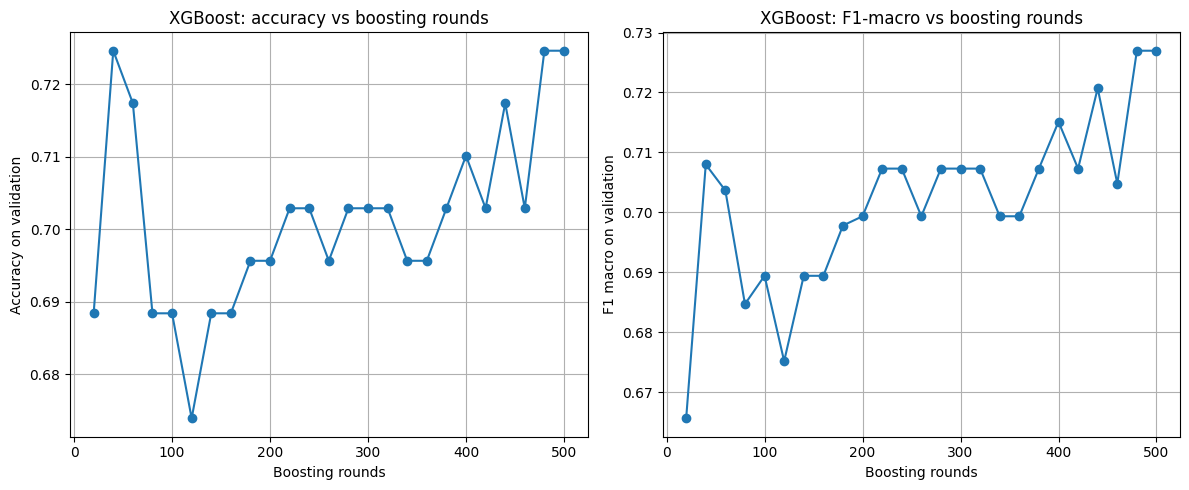

Final test accuracy: 0.7676767676767676
Final test F1-macro: 0.7628603382673894


In [17]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

num_classes = len(np.unique(y_train_encoded))

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train_encoded,
    test_size=0.25,
    stratify=y_train_encoded,
    random_state=42
)

dtrain = xgb.DMatrix(X_fit, label=y_fit)
dval = xgb.DMatrix(X_val, label=y_val)

params = {
    "objective": "multi:softprob",
    "num_class": num_classes,
    "eval_metric": "mlogloss",
    "eta": 0.1,
    "max_depth": 3,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "seed": 42  # фиксируем сид, но без np.random в коде
}

n_estimators_range = np.arange(20, 501, 20)
xgb_acc, xgb_f1 = [], []

for n in n_estimators_range:
    booster = xgb.train(
        params=params,
        dtrain=dtrain,
        num_boost_round=int(n)
    )
    y_proba = booster.predict(dval)
    y_pred = np.argmax(y_proba, axis=1)

    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average="macro")

    xgb_acc.append(acc)
    xgb_f1.append(f1)
    print(f"Rounds: {n:3d} | accuracy: {acc:.4f} | F1-macro: {f1:.4f}")

best_idx = int(np.argmax(xgb_f1))
best_n_estimators_xgb = int(n_estimators_range[best_idx])

print("\nBest number of trees for XGBoost (by F1-macro):", best_n_estimators_xgb)
print("Best accuracy: {:.4f}".format(xgb_acc[best_idx]))
print("Best F1-macro: {:.4f}".format(xgb_f1[best_idx]))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(n_estimators_range, xgb_acc, marker="o")
plt.xlabel("Boosting rounds")
plt.ylabel("Accuracy on validation")
plt.title("XGBoost: accuracy vs boosting rounds")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(n_estimators_range, xgb_f1, marker="o")
plt.xlabel("Boosting rounds")
plt.ylabel("F1 macro on validation")
plt.title("XGBoost: F1-macro vs boosting rounds")
plt.grid(True)

plt.tight_layout()
plt.show()

# Финальная модель
dtrain_full = xgb.DMatrix(X_train, label=y_train_encoded)
dtest = xgb.DMatrix(X_test, label=y_test_encoded)

final_booster = xgb.train(
    params=params,
    dtrain=dtrain_full,
    num_boost_round=best_n_estimators_xgb
)

y_proba = final_booster.predict(dtest)
y_pred = np.argmax(y_proba, axis=1)

print("Final test accuracy:", accuracy_score(y_test_encoded, y_pred))
print("Final test F1-macro:", f1_score(y_test_encoded, y_pred, average="macro"))


Для подбора количества деревьев разделил обучающую выборку на тренировочную и валидационную. Проверил разные количества итераций от 20 до 500 с шагом 20.

По графикам видно что качество сначала растет, максимальный F1 получается при 480 итерациях и составляет 0.7270.

После выбора оптимального количества итераций обучил модель на всей тренировочной выборке и проверил на тестовой. Accuracy получилась 0.7677, а F1 0.7629. Результат немного хуже чем на валидации, но это уже оценка на данных которые не использовались при подборе параметров.